# LeetCode #1222: Queens That Can Attack the King

https://leetcode.com/problems/queens-that-can-attack-the-king/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(q \cdot 8 \cdot 8)$ | $O(1)$ |
| **Optimal: 8-Direction BFS from King ★** | $O(64)$ | $O(q)$ |

---

## Understanding the Methods

### Brute Force
For each queen, check whether it lies on the same row, column, or diagonal as the king and is not blocked by another queen. Requires cross-queen comparisons that are awkward to manage.

### Optimal: 8-Direction BFS from King ★
Store all queen positions in a hash set. Then walk outward from the king in each of the 8 directions, stopping the first time a queen is encountered. Because a blocking queen hides all queens behind it, at most one queen per direction can attack — giving at most 8 results regardless of board size.

**Constraints:**
* $1 \leq queens.length \leq 63$
* $0 \leq queens[i][j] \leq 7$ (8x8 board)
* Only one king on the board


## Solutions

### C#


In [ ]:
public IList<IList<int>> QueensAttacktheKing(int[][] queens, int[] king) {
    var queenSet = new HashSet<(int,int)>();
    foreach (var q in queens) queenSet.Add((q[0], q[1]));
    var result = new List<IList<int>>();
    int[] dirs = {-1,0,1};
    // Expand outward from king in each of the 8 compass directions
    for (int dr = -1; dr <= 1; dr++) {
        for (int dc = -1; dc <= 1; dc++) {
            if (dr == 0 && dc == 0) continue;
            int r = king[0] + dr, c = king[1] + dc;
            while (r >= 0 && r < 8 && c >= 0 && c < 8) {
                // First queen found in this direction blocks all others behind it
                if (queenSet.Contains((r, c))) {
                    result.Add(new List<int> { r, c });
                    break;
                }
                r += dr; c += dc;
            }
        }
    }
    return result;
}


### Python


In [ ]:
def queens_attack_the_king(queens: list[list[int]], king: list[int]) -> list[list[int]]:
    queen_set = {(q[0], q[1]) for q in queens}
    result = []
    # Walk all 8 directions from the king, stop at the first queen encountered
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == dc == 0:
                continue
            r, c = king[0] + dr, king[1] + dc
            while 0 <= r < 8 and 0 <= c < 8:
                if (r, c) in queen_set:
                    result.append([r, c])
                    break
                r += dr
                c += dc
    return result


### Go


In [ ]:
func queensAttacktheKing(queens [][]int, king []int) [][]int {
    type pair struct{ r, c int }
    queenSet := map[pair]bool{}
    for _, q := range queens {
        queenSet[pair{q[0], q[1]}] = true
    }
    result := [][]int{}
    // Cast rays in all 8 directions; record only the first queen hit per ray
    for dr := -1; dr <= 1; dr++ {
        for dc := -1; dc <= 1; dc++ {
            if dr == 0 && dc == 0 { continue }
            r, c := king[0]+dr, king[1]+dc
            for r >= 0 && r < 8 && c >= 0 && c < 8 {
                if queenSet[pair{r, c}] {
                    result = append(result, []int{r, c})
                    break
                }
                r += dr
                c += dc
            }
        }
    }
    return result
}


### Rust


In [ ]:
use std::collections::HashSet;

pub fn queens_attack_the_king(queens: Vec<Vec<i32>>, king: Vec<i32>) -> Vec<Vec<i32>> {
    let queen_set: HashSet<(i32,i32)> = queens.iter().map(|q| (q[0], q[1])).collect();
    let mut result = Vec::new();
    // Eight compass directions searched outward from the king's position
    for dr in -1i32..=1 {
        for dc in -1i32..=1 {
            if dr == 0 && dc == 0 { continue; }
            let (mut r, mut c) = (king[0] + dr, king[1] + dc);
            while r >= 0 && r < 8 && c >= 0 && c < 8 {
                if queen_set.contains(&(r, c)) {
                    result.push(vec![r, c]);
                    break;
                }
                r += dr;
                c += dc;
            }
        }
    }
    result
}


## Example Scenarios

### 1. Common Case — Three Rays Land on a Queen

**Input:** `queens = [[0,1],[1,0],[4,0],[0,4],[3,3],[2,4]]`, `king = [0,0]`

The king sits in the top-left corner, so only 3 of the 8 rays stay on the board. Right hits $(0,1)$ immediately, down hits $(1,0)$ immediately, and down-right walks $(1,1), (2,2)$ (both empty) before finding $(3,3)$. Queens $(4,0)$ and $(0,4)$ are hidden behind the closer $(1,0)$ and $(0,1)$, and $(2,4)$ shares no line with the king. **Output: `[[0,1],[1,0],[3,3]]`** — 3 queens.

### 2. Slightly Complex — Only Two of Six Queens Are on a Line

**Input:** `queens = [[0,0],[1,1],[2,2],[3,3],[7,0],[7,6]]`, `king = [3,4]`

Left walks to $(3,3)$ and stops. Down-left walks $(4,3), (5,2), (6,1)$ and lands on $(7,0)$ at distance 4 — the longest useful ray here. Up-left goes $(2,3), (1,2), (0,1)$ and finds nothing, so the diagonal $(0,0), (1,1), (2,2)$ chain is invisible to the king: those squares are on the *wrong* diagonal. **Output: `[[3,3],[7,0]]`** — only 2 queens despite 6 on the board.

### 3. Edge Case: Time Factor — Board Packed with 63 Queens

**Input:** all 63 non-king squares hold a queen, `king = [3,3]`

Every ray terminates after a single step because the 8 neighbours of the king are all queens. This is the *maximum* output size: $(2,2), (2,3), (2,4), (3,2), (3,4), (4,2), (4,3), (4,4)$. Work is $O(8)$ steps, not $O(q)$ — the answer is capped at **8** no matter how many queens exist, which is exactly why ray-walking beats comparing every queen pair. **Output: 8 queens.**

### 4. Edge Case: Space Factor — Single Queen at Maximum Distance

**Input:** `queens = [[7,7]]`, `king = [0,0]`

Seven of the eight rays either leave the board instantly or scan to the edge and find nothing; the down-right ray walks the full 7 squares $(1,1) \to (7,7)$. This is the worst case for *total steps scanned* (longest rays, fewest early exits) but the best case for output space. **Output: `[[7,7]]`** — 1 queen.

### 5. Almost-Impossible but Plausible — Symmetric Corner/Edge Decoys

**Input:** `queens = [[0,0],[0,7],[7,0],[7,7],[0,4],[4,0],[4,7],[7,4]]`, `king = [4,4]`

Eight queens arranged symmetrically *looks* like all 8 rays should score, but only 6 do. The four cardinal rays find $(4,0), (4,7), (0,4), (7,4)$; up-left finds $(0,0)$ and down-right finds $(7,7)$. The up-right ray passes $(3,5), (2,6), (1,7)$ and exits the board — $(0,7)$ would need an 8th diagonal step that does not exist. Down-left likewise misses $(7,0)$, which is $\pm 4$ in rows but $-4$ in columns from a king whose anti-diagonal runs the other way. **Output: 6 queens, not 8** — the near-miss decoy.


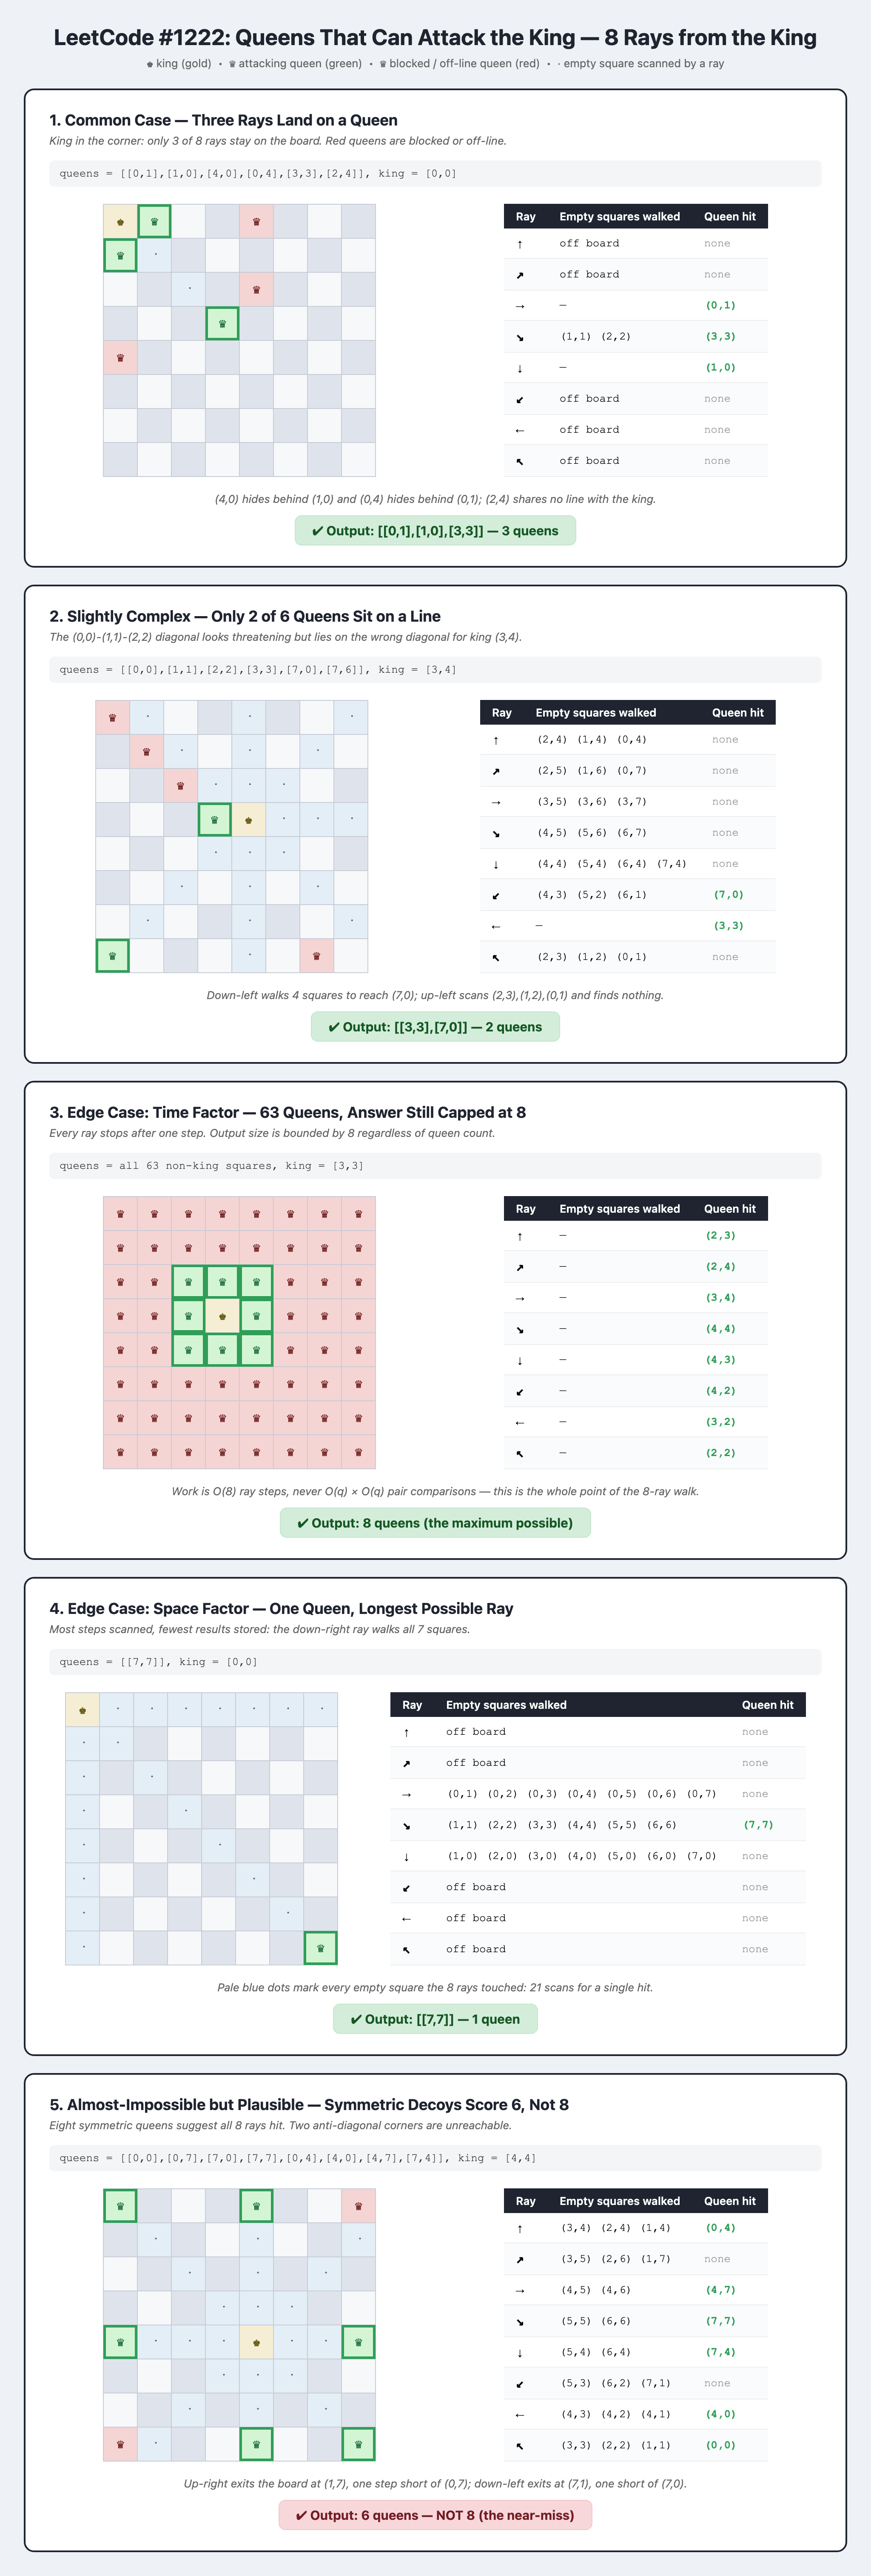